In [32]:
from pathlib import Path

import polars as pl
import seaborn as sns

In [36]:
dev_version_path = Path.cwd().parent / ".dev" / "storage" / "dev" / "nightly"
capcost_og = pl.read_csv(Path(dev_version_path, "raw/bluesky/cap_cost.csv")).rename(
    {"CapCost": "capital_cost_usd_per_mw"}
)
capcost = pl.read_csv(Path(dev_version_path, "out/parameters/capital_cost.csv"))

In [58]:
tech_map = {
    1: "coal",
    2: "petroleum",
    3: "ng_combustion",
    4: "ng_cc",
    6: "nuclear",
    7: "biomass",
    8: "geothermal",
    9: "waste",
    10: "hydro",
    11: "hydro_pumped_storage",
    12: "storage",
    13: "offshore_wind",
    14: "onshore_wind",
    15: "pv",
}

In [39]:
# Region and step are the same for all files, so ignore them.
comp = (
    capcost.join(
        capcost_og, how="left", on=["region", "tech", "year", "step"], suffix="_orig"
    )
    .drop(["region", "step", "notes"])
    .unique(maintain_order=True)
)

In [65]:
df_long = comp.melt(
    id_vars=["tech", "year"],
    value_vars=["capital_cost_usd_per_mw", "capital_cost_usd_per_mw_orig"],
    variable_name="data_source",
    value_name="capital_cost",
).with_columns(
    data_source=pl.col("data_source").replace(
        {"capital_cost_usd_per_mw": "cnems", "capital_cost_usd_per_mw_orig": "bluesky"}
    ),
    tech_lab=pl.col("tech").replace_strict(tech_map, return_dtype=pl.String),
)

/tmp/ipykernel_42476/2874212760.py:1: DeprecationWarning: `DataFrame.melt` is deprecated; use `DataFrame.unpivot` instead, with `index` instead of `id_vars` and `on` instead of `value_vars`
  df_long = comp.melt(


In [66]:
df_long

tech,year,data_source,capital_cost,tech_lab
i64,i64,str,f64,str
1,2023,"""cnems""",3.1837e6,"""coal"""
1,2024,"""cnems""",3.1662e6,"""coal"""
1,2025,"""cnems""",3.1487e6,"""coal"""
1,2026,"""cnems""",3.1312e6,"""coal"""
1,2027,"""cnems""",3.1137e6,"""coal"""
…,…,…,…,…
15,2046,"""bluesky""",734940.0,"""pv"""
15,2047,"""bluesky""",707720.0,"""pv"""
15,2048,"""bluesky""",680500.0,"""pv"""


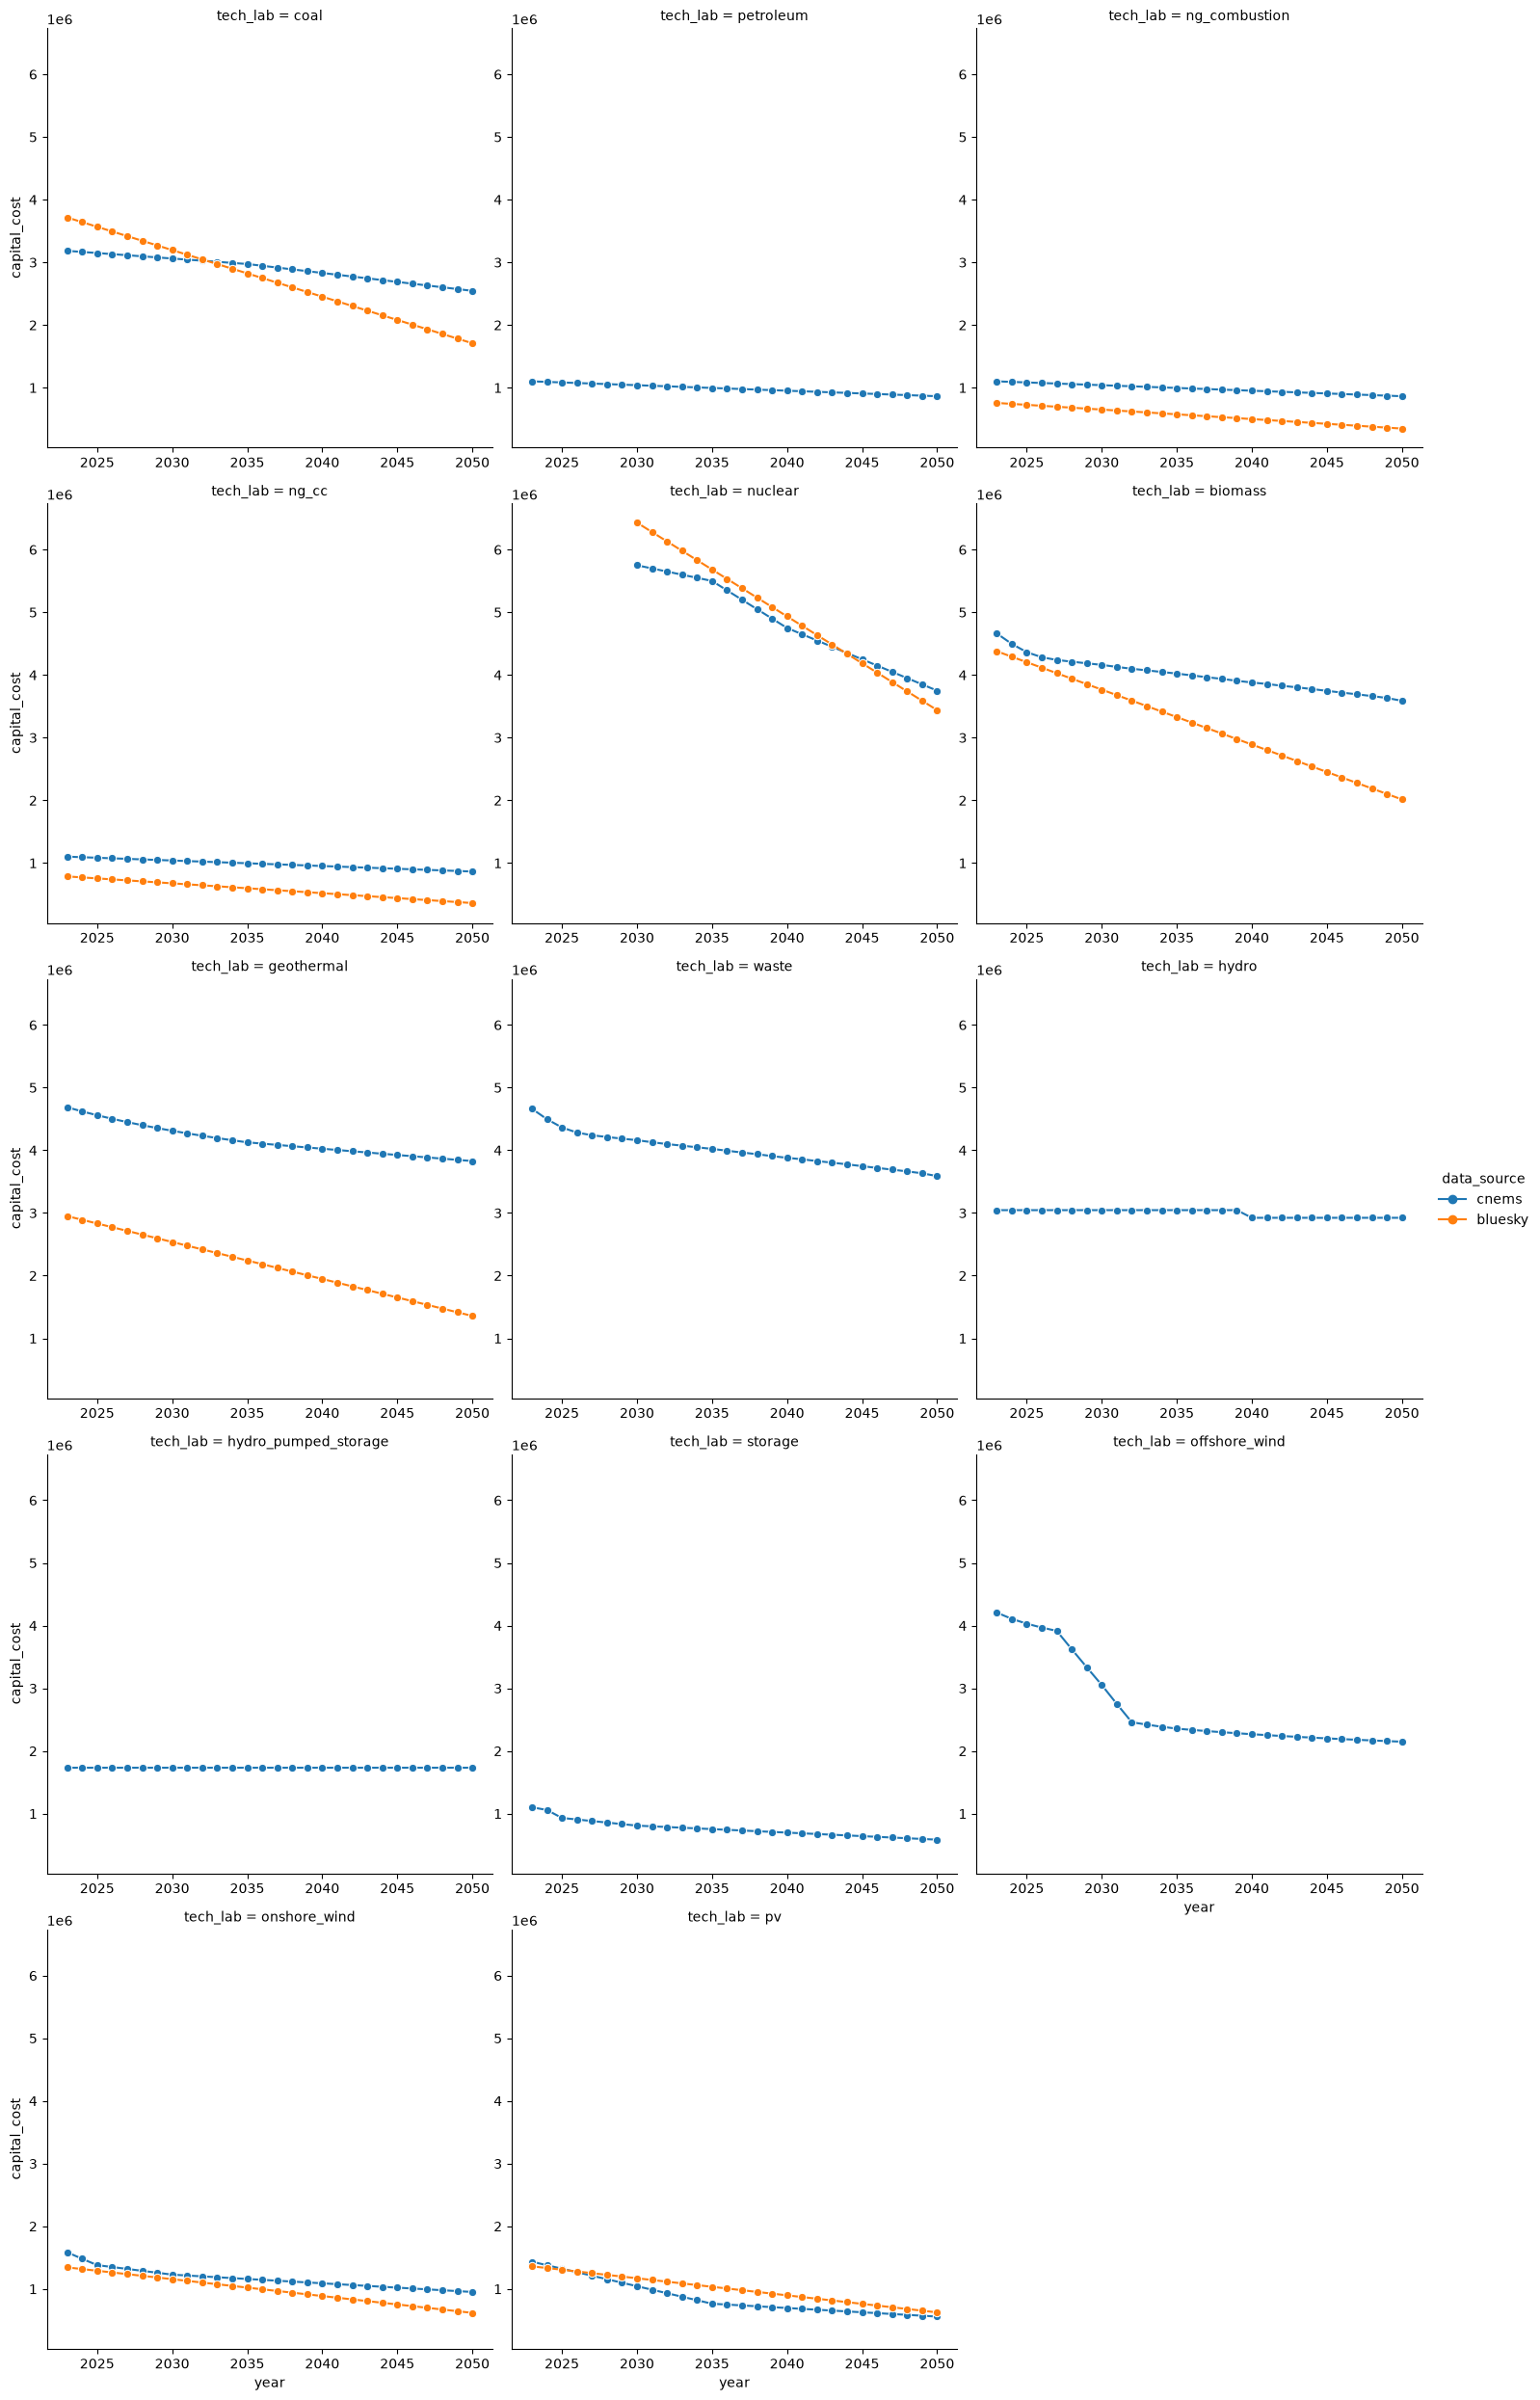

In [82]:
g = sns.relplot(
    data=df_long,
    x="year",
    y="capital_cost",
    hue="data_source",
    col="tech_lab",
    kind="line",
    marker="o",
    col_wrap=3,
)
for ax in g.axes.flat:
    ax.tick_params(axis="x", labelbottom=True)
    ax.tick_params(axis="y", labelleft=True)

In [84]:
pct_diff_df = comp.with_columns(
    pct_diff=100
    * (pl.col("capital_cost_usd_per_mw") - pl.col("capital_cost_usd_per_mw_orig"))
    / pl.col("capital_cost_usd_per_mw_orig"),
    tech_lab=pl.col("tech").replace_strict(tech_map, return_dtype=pl.String),
)

In [85]:
pct_diff_df = pct_diff_df.filter(pl.col("pct_diff").is_not_null().any().over("tech"))

In [91]:
pct_diff_df.filter(pl.col("tech") == 5)

tech,year,capital_cost_usd_per_mw,capital_cost_usd_per_mw_orig,pct_diff,tech_lab
i64,i64,f64,i64,f64,str


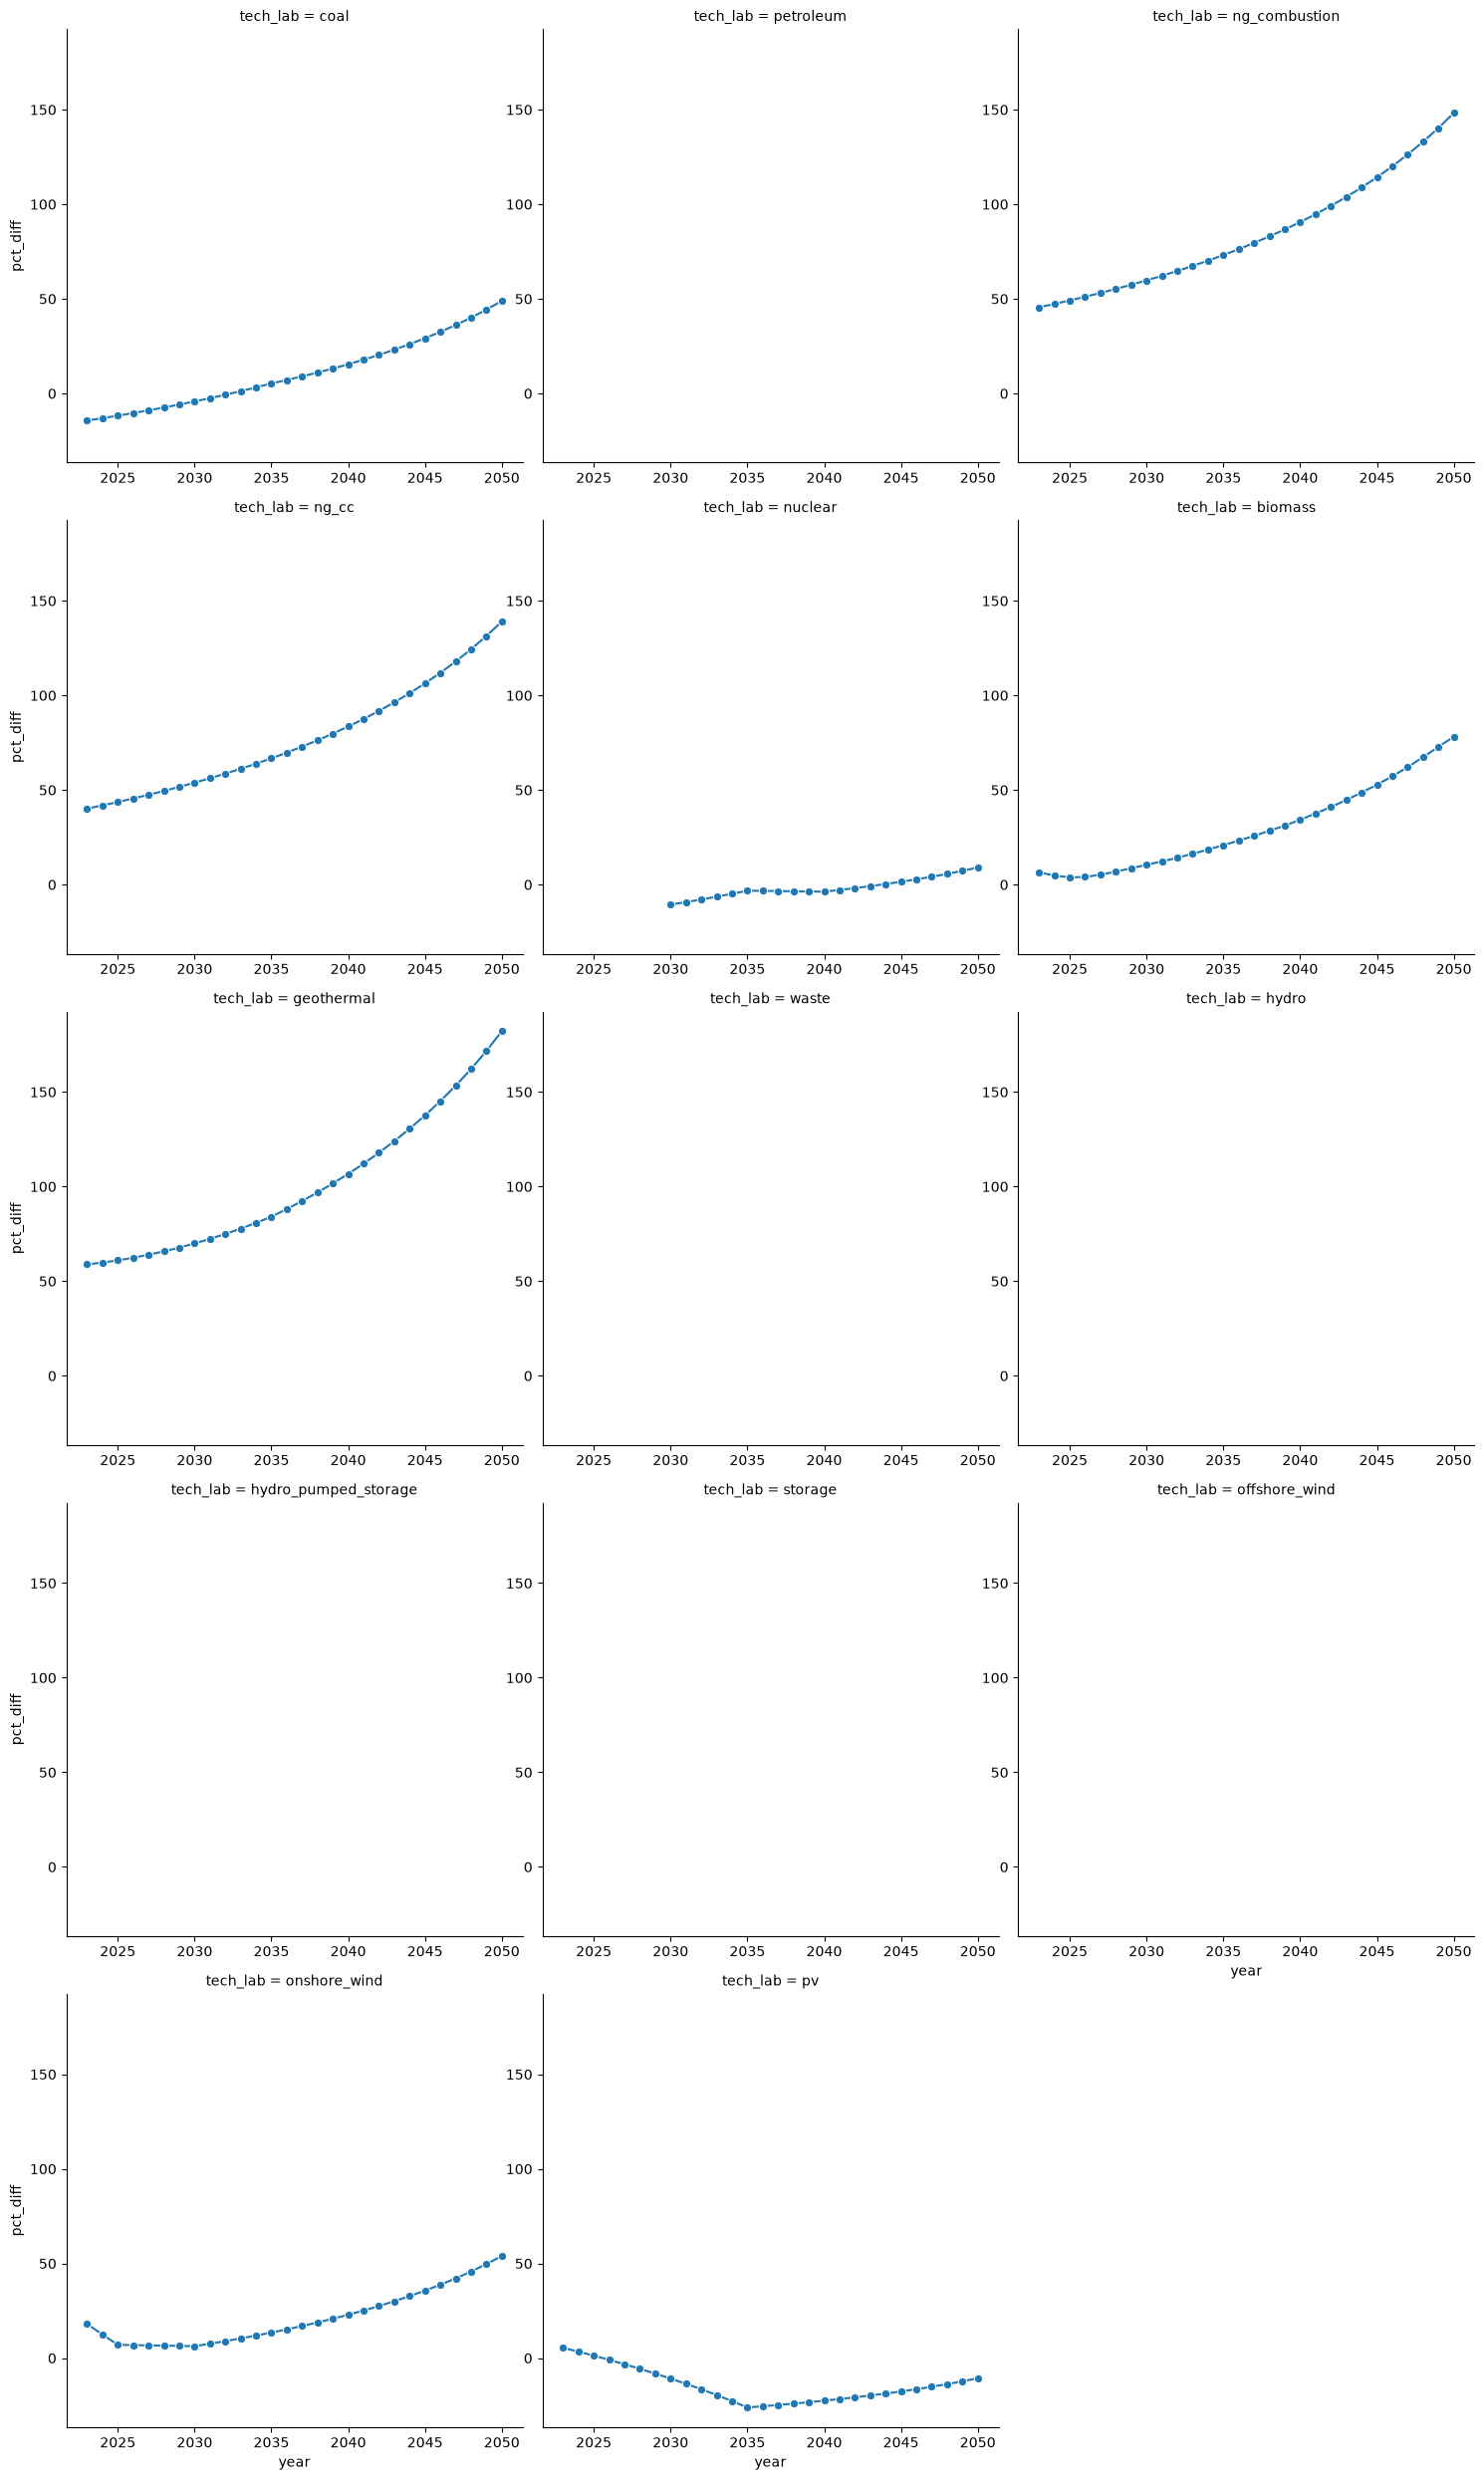

In [86]:
gr = sns.relplot(
    data=comp,
    x="year",
    y="pct_diff",
    col="tech_lab",
    kind="line",
    marker="o",
    col_wrap=3,
)

for ax in gr.axes.flat:
    ax.tick_params(axis="x", labelbottom=True)
    ax.tick_params(axis="y", labelleft=True)